# Module 00 — Tools of the Trade: NumPy, pandas, matplotlib

**Learning goals**
- Understand *why* ML code uses NumPy arrays instead of Python lists (vectorization).
- Create, reshape, index and slice arrays; use boolean masks.
- Understand the `axis` argument and **broadcasting** — these two ideas show up in every later module.
- Load and manipulate tabular data with pandas (`loc`, `iloc`, filtering, `groupby`).
- Make the basic plots you'll use constantly: line, scatter, histogram, subplots.

You already know Python, so we skip language basics and focus on the "array mindset".

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# A Generator with a fixed seed -> the same "random" numbers every run (reproducible results).
rng = np.random.default_rng(42)

## 1. Why NumPy? Vectorization

In ML we apply the same operation to thousands or millions of numbers. A Python `for` loop handles one
number at a time and interprets each step. NumPy stores numbers in a contiguous block of memory and runs the
loop in compiled C code. Writing operations on *whole arrays* instead of elements is called **vectorization**.

In [2]:
n = 1_000_000
py_list = list(range(n))
arr = np.arange(n)

start = time.perf_counter()
squared_list = [x * x for x in py_list]
t_list = time.perf_counter() - start

start = time.perf_counter()
squared_arr = arr * arr          # one expression, applied element-wise to all 1M values
t_arr = time.perf_counter() - start

print(f"list comprehension: {t_list*1000:.1f} ms")
print(f"numpy vectorized:   {t_arr*1000:.1f} ms  (~{t_list/t_arr:.0f}x faster)")

list comprehension: 14.9 ms
numpy vectorized:   1.4 ms  (~11x faster)


## 2. Creating arrays: shape and dtype

Every array has a **shape** (a tuple of sizes per dimension) and a **dtype** (the type of every element; all
elements share one type).

In ML, the convention is:
- `X` — a 2-D array of shape `(n_samples, n_features)`: one **row per example**, one **column per feature**.
- `y` — a 1-D array of shape `(n_samples,)`: the target value for each row.

In [3]:
v = np.array([1.0, 2.0, 3.0])                 # 1-D: a vector
M = np.array([[1, 2, 3],
              [4, 5, 6]])                      # 2-D: a matrix with 2 rows, 3 columns

print("v:", v, "shape:", v.shape, "dtype:", v.dtype)
print("M shape:", M.shape, "ndim:", M.ndim, "dtype:", M.dtype)

v: [1. 2. 3.] shape: (3,) dtype: float64
M shape: (2, 3) ndim: 2 dtype: int64


In [4]:
# Handy constructors
print(np.zeros((2, 3)))
print(np.ones(4))
print(np.arange(0, 10, 2))            # like range(): start, stop (exclusive), step
print(np.linspace(0, 1, 5))           # 5 evenly spaced points, stop is INCLUDED
print(np.eye(3))                      # identity matrix (1s on the diagonal)
print(rng.normal(loc=0, scale=1, size=(2, 3)))  # samples from a normal (bell-curve) distribution

[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1. 1.]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[ 0.30471708 -1.03998411  0.7504512 ]
 [ 0.94056472 -1.95103519 -1.30217951]]


### Reshaping

`reshape` changes how the same numbers are laid out. `-1` means "work out this dimension for me".
A very common need: turning a 1-D array of shape `(n,)` into a column `(n, 1)` because sklearn wants a 2-D `X`.

In [5]:
a = np.arange(12)
print(a.reshape(3, 4))
print(a.reshape(-1, 6).shape)   # -1 -> numpy computes 12/6 = 2

x = np.array([5, 6, 7])
print(x.shape, "->", x.reshape(-1, 1).shape)   # (3,) -> (3, 1): one feature column
print(x[:, np.newaxis].shape)                  # same thing, another common idiom

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2, 6)
(3,) -> (3, 1)
(3, 1)


## 3. Indexing, slicing and boolean masks

In [6]:
M = np.arange(1, 13).reshape(3, 4)
print(M)
print("row 0:        ", M[0])          # first row
print("column 1:     ", M[:, 1])       # ':' means "all rows"
print("element (2,3):", M[2, 3])
print("rows 0-1, cols 1-2:\n", M[0:2, 1:3])

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
row 0:         [1 2 3 4]
column 1:      [ 2  6 10]
element (2,3): 12
rows 0-1, cols 1-2:
 [[2 3]
 [6 7]]


A **boolean mask** is an array of `True/False` with the same shape. Using it as an index keeps only the `True`
positions. This is how we filter data without loops.

In [7]:
scores = np.array([55, 82, 91, 47, 76])
mask = scores >= 60                    # comparison is element-wise -> boolean array
print(mask)
print(scores[mask])                    # only passing scores
print(scores[(scores > 50) & (scores < 80)])   # combine with & | ~  (and parentheses are required!)

# Fancy indexing: pass a list/array of positions
print(scores[[0, 2, 4]])

[False  True  True False  True]
[82 91 76]
[55 76]
[55 91 76]


⚠️ **Views vs copies:** slicing (`a[1:3]`) returns a *view* that shares memory with the original;
modifying it modifies the original. Boolean/fancy indexing returns a *copy*. Use `.copy()` when in doubt.

In [8]:
a = np.arange(5)
view = a[1:3]
view[0] = 99
print(a)          # a changed too!

[ 0 99  2  3  4]


## 4. The `axis` argument

Aggregations (`sum`, `mean`, `max`, `std`, ...) can work over the whole array or along an axis.

- `axis=0` → collapse the **rows** → one result **per column** (e.g. the mean of each feature).
- `axis=1` → collapse the **columns** → one result **per row** (e.g. a total per example).

Memory trick: the axis you pass is the one that *disappears* from the shape.

In [9]:
X = np.array([[1.0, 200.0],
              [2.0, 300.0],
              [3.0, 400.0]])   # 3 samples, 2 features
print("shape:", X.shape)
print("overall mean:", X.mean())
print("per-feature mean (axis=0):", X.mean(axis=0), "shape", X.mean(axis=0).shape)
print("per-sample sum  (axis=1):", X.sum(axis=1), "shape", X.sum(axis=1).shape)

shape: (3, 2)
overall mean: 151.0
per-feature mean (axis=0): [  2. 300.] shape (2,)
per-sample sum  (axis=1): [201. 302. 403.] shape (3,)


## 5. Broadcasting

When you combine arrays of different shapes, NumPy "stretches" the smaller one to match, without copying data.
Rule: compare shapes **right to left**; two dimensions are compatible if they are equal or one of them is 1.

The most important ML use is **standardization**: subtract each column's mean and divide by its std.
`X` has shape `(3, 2)` and `X.mean(axis=0)` has shape `(2,)`. Aligned on the right, `(3, 2)` vs `(2,)` matches,
so the mean is subtracted from every row.

In [10]:
mu = X.mean(axis=0)            # shape (2,)
sigma = X.std(axis=0)          # shape (2,)
X_std = (X - mu) / sigma       # (3,2) - (2,) -> broadcast across rows
print(X_std)
print("new means:", X_std.mean(axis=0).round(10))   # ~0 for every feature
print("new stds: ", X_std.std(axis=0))              # 1 for every feature

[[-1.22474487 -1.22474487]
 [ 0.          0.        ]
 [ 1.22474487  1.22474487]]
new means: [0. 0.]
new stds:  [1. 1.]


In [11]:
# Per-ROW operations need the extra dimension so shapes line up: (3,2) vs (3,1)
row_totals = X.sum(axis=1, keepdims=True)    # keepdims=True keeps shape (3,1) instead of (3,)
print(row_totals.shape)
print(X / row_totals)                         # each row now sums to 1

(3, 1)
[[0.00497512 0.99502488]
 [0.00662252 0.99337748]
 [0.00744417 0.99255583]]


## 6. A few more operations you'll see constantly

In [12]:
a = np.array([3, 1, 4, 1, 5, 9, 2, 6])
print("argmax:", a.argmax(), "(index of the largest value)")
print("argsort:", np.argsort(a), "(indices that would sort a)")
print("unique:", np.unique(a, return_counts=True))
print("where:", np.where(a > 3, "big", "small"))   # vectorized if/else
print("clip:", np.clip(a, 2, 5))                    # limit values into [2, 5]

A = np.array([[1, 2], [3, 4]])
B = np.array([[10, 20], [30, 40]])
print("element-wise A*B:\n", A * B)
print("matrix product A@B:\n", A @ B)    # @ is matrix multiplication; Module 01 explains it

argmax: 5 (index of the largest value)
argsort: [1 3 6 0 2 4 7 5] (indices that would sort a)
unique: (array([1, 2, 3, 4, 5, 6, 9]), array([2, 1, 1, 1, 1, 1, 1]))
where: ['small' 'small' 'big' 'small' 'big' 'big' 'small' 'big']
clip: [3 2 4 2 5 5 2 5]
element-wise A*B:
 [[ 10  40]
 [ 90 160]]
matrix product A@B:
 [[ 70 100]
 [150 220]]


## 7. pandas: labeled tables

NumPy arrays hold numbers. A pandas **DataFrame** is a table with named columns, each of which can have its own
dtype. A single column is a **Series**. Most real datasets start life as DataFrames and are turned into NumPy arrays
right before modelling.

In [13]:
df = pd.DataFrame({
    "name":   ["Asha", "Ben", "Chen", "Dina", "Eli", "Fay"],
    "city":   ["Pune", "Leeds", "Pune", "Leeds", "Oslo", "Pune"],
    "age":    [23, 35, 31, 28, 42, 19],
    "salary": [41000, 62000, 58000, 49000, 81000, 30000],
})
df

,name,city,age,salary
0,Asha,Pune,23,41000
1,Ben,Leeds,35,62000
2,Chen,Pune,31,58000
3,Dina,Leeds,28,49000
4,Eli,Oslo,42,81000
5,Fay,Pune,19,30000


In [14]:
df.info()             # column dtypes, non-null counts
df.describe()         # summary stats of numeric columns

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   name    6 non-null      str  
 1   city    6 non-null      str  
 2   age     6 non-null      int64
 3   salary  6 non-null      int64
dtypes: int64(2), str(2)
memory usage: 324.0 bytes


,age,salary
count,6.000000,6.000000
mean,29.666667,53500.000000
std,8.286535,17762.319668
min,19.000000,30000.000000
25%,24.250000,43000.000000
50%,29.500000,53500.000000
75%,34.000000,61000.000000
max,42.000000,81000.000000


### Selecting data: `loc` vs `iloc`
- `df["col"]` → one column (Series); `df[["a", "b"]]` → several columns (DataFrame).
- `df.loc[rows, cols]` → select by **label** (index labels and column names). Slices *include* the end label.
- `df.iloc[rows, cols]` → select by **integer position**, like NumPy. Slices *exclude* the end.

In [15]:
print(df["age"].mean())
print(df.loc[0:2, ["name", "age"]])     # labels 0,1,2 (inclusive!)
print(df.iloc[0:2, 0:2])                # positions 0,1

29.666666666666668
   name  age
0  Asha   23
1   Ben   35
2  Chen   31
   name   city
0  Asha   Pune
1   Ben  Leeds


In [16]:
# Filtering with boolean masks works just like NumPy
df[(df["city"] == "Pune") & (df["age"] > 20)]

,name,city,age,salary
0,Asha,Pune,23,41000
2,Chen,Pune,31,58000


In [17]:
# New columns are vectorized expressions
df["salary_k"] = df["salary"] / 1000
df["is_senior"] = df["age"] >= 30
df.head()

,name,city,age,salary,salary_k,is_senior
0,Asha,Pune,23,41000,41.0,False
1,Ben,Leeds,35,62000,62.0,True
2,Chen,Pune,31,58000,58.0,True
3,Dina,Leeds,28,49000,49.0,False
4,Eli,Oslo,42,81000,81.0,True


### groupby: split → apply → combine
`groupby` splits rows into groups by a key, applies an aggregation to each group, and combines the results.

In [18]:
df.groupby("city")["salary"].agg(["count", "mean", "max"])

,count,mean,max
city,,,
Leeds,2,55500.0,62000
Oslo,1,81000.0,81000
Pune,3,43000.0,58000


In [19]:
# From DataFrame to the NumPy X/y that ML libraries expect
X = df[["age", "salary"]].to_numpy()
y = df["is_senior"].to_numpy()
print(X.shape, y.shape, X.dtype)

(6, 2) (6,) int64


## 8. Plotting with matplotlib and seaborn

Use the object-oriented style `fig, ax = plt.subplots(...)` and call methods on `ax`. It scales well to
multi-panel figures. seaborn builds on matplotlib and makes statistical plots in one line.

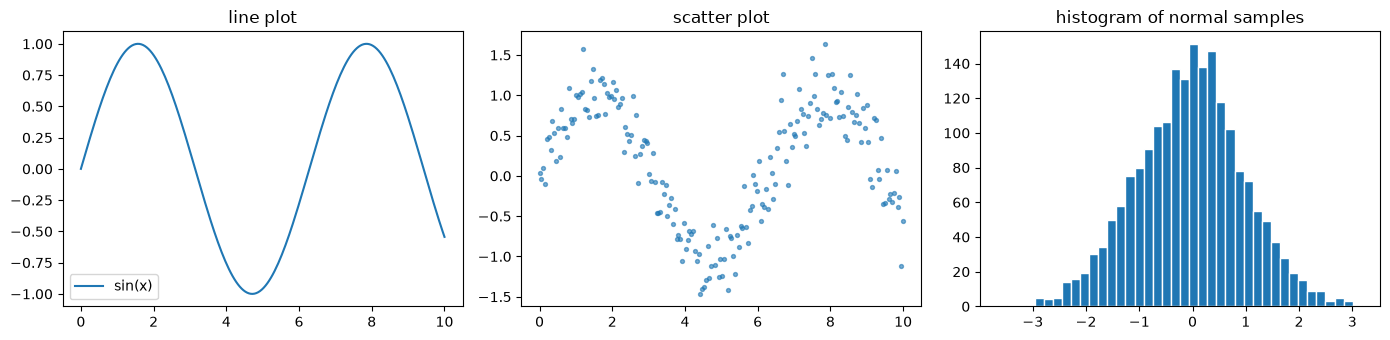

In [20]:
x = np.linspace(0, 10, 200)
noisy = np.sin(x) + rng.normal(0, 0.3, size=x.shape)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))   # 1 row, 3 columns of plots
axes[0].plot(x, np.sin(x), label="sin(x)")
axes[0].legend(); axes[0].set_title("line plot")

axes[1].scatter(x, noisy, s=8, alpha=0.6)
axes[1].set_title("scatter plot")

axes[2].hist(rng.normal(size=2000), bins=40, edgecolor="white")
axes[2].set_title("histogram of normal samples")

fig.tight_layout()   # stops titles/labels overlapping
plt.show()

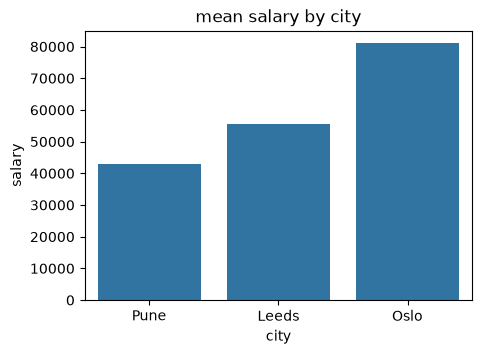

In [21]:
# seaborn works directly with DataFrames: refer to columns by name
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(data=df, x="city", y="salary", ax=ax, errorbar=None)
ax.set_title("mean salary by city")
plt.show()

## Common pitfalls
- **Shape `(n,)` vs `(n, 1)`.** sklearn wants a 2-D `X`. Use `.reshape(-1, 1)` for a single feature.
- **Wrong `axis`.** Always print `.shape` after an aggregation to confirm you got the shape you expected.
- **Using `and`/`or` with arrays.** Use `&`, `|` and `~`, and put each condition in parentheses.
- **Changing a slice changes the original.** Call `.copy()` if you need an independent array.
- **`loc` slices include the end label; `iloc` slices exclude the end position.**
- **Integer division surprises.** An `int` array stays `int` until a float enters the calculation. Check `.dtype`.

## Recap
- Vectorized NumPy code is fast and concise, so prefer whole-array operations to loops.
- `X` has shape `(n_samples, n_features)` and `y` has shape `(n_samples,)`.
- `axis=0` gives one result per column and `axis=1` gives one per row.
- Broadcasting lets you standardize all columns at once with `(X - X.mean(0)) / X.std(0)`.
- Use pandas for loading and wrangling, then `.to_numpy()` for modelling.

**Next:** open `exercises.ipynb`. Fill in each `TODO`, then run the check cell below it.

## 📚 Further resources
🎥 video · 📖 book or guide · 📄 paper. Watching the videos alongside the lesson is the best way to use them.

- 🎥 [Python NumPy Tutorial for Beginners (freeCodeCamp)](https://www.youtube.com/watch?v=QUT1VHiLmmI)
- 🎥 [Complete Python Pandas Data Science Tutorial (Keith Galli)](https://www.youtube.com/watch?v=vmEHCJofslg)
- 📖 [NumPy: the absolute basics for beginners (official docs)](https://numpy.org/doc/stable/user/absolute_beginners.html)
- 📖 [Python Data Science Handbook, chapters 2–4 (free online)](https://jakevdp.github.io/PythonDataScienceHandbook/)
- 📄 [Harris et al. (2020), *Array programming with NumPy*, Nature (optional)](https://doi.org/10.1038/s41586-020-2649-2)